# Banksy

- **Creator**: Sebastian Birk (sb75@sanger.ac.uk.com)
- **Date of Creation:** 12.07.2024
- **Date of Last Modification:** 18.07.2024 (Sebastian Birk; <sb75@sanger.ac.uk.com>)

- The Banksy source code is available at https://github.com/prabhakarlab/Banksy (R) and https://github.com/prabhakarlab/Banksy_py (Python).
- The corresponding publication is "Singhal, V. et al. BANKSY unifies cell typing and tissue domain segmentation for scalable spatial omics data analysis. Nat. Genet. (2024) doi:10.1038/s41588-024-01664-3".
- The workflow of this notebook follows the tutorial from https://github.com/prabhakarlab/Banksy_py/blob/main/slideseqv2_analysis.ipynb.

- Run this notebook in the nichecompass-reproducibility environment, installable from ```('../../../envs/environment.yaml')```. In addition, it is required to clone the Banksy_py repo from GitHub as follows:
    - ```cd analysis/benchmarking```
    - ```git clone https://github.com/prabhakarlab/Banksy_py.git```

## 1. Setup

### 1.1 Import Libraries

In [1]:
%load_ext autoreload
%autoreload 2

In [51]:
import sys
sys.path.append("../../utils")

In [57]:
import warnings
import gc
import os
import time
from datetime import datetime

import anndata as ad
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import squidpy as sq

from banksy.initialize_banksy import initialize_banksy
from banksy_utils.umap_pca import pca_umap
from banksy.embed_banksy import generate_banksy_matrix

In [53]:
from analysis_utils import *
from benchmarking_utils import max_overlap_plot

In [78]:
import sklearn.metrics as skm
from scib_metrics import ilisi_knn
from scib_metrics.nearest_neighbors import pynndescent

### 1.2 Configure Paths

In [4]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'

### 1.3 Define Config

In [55]:
n_pcs = None
n_neighs = 10
spot_sizes = {'MERFISH': 20,
              'STARmap PLUS': 100}
batch_key = 'batch'

### 1.4 Run Notebook Setup

In [6]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [7]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [8]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [9]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

In [10]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/banksy', exist_ok=True)

## 1.5 Define Functions

In [11]:
def _combine_neighbor_graphs(adata: ad.AnnData,
                             n_neighs: int | None,
                             radius: float | None,
                             delaunay: bool,
                             include_self_loop: bool,
                             ) -> ad.AnnData:
    """
    Helper function to combine neighbor graphs computed using different
    methods.
    """
    if n_neighs is not None:
        # Compute knn spatial neighborhood graph
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                n_neighs=n_neighs,
                                set_diag=include_self_loop,
                                ) 
        knn_conn = adata.obsp['spatial_connectivities']  
    if radius is not None:
        # Compute spatial neighborhood graph with radius
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                radius=radius,
                                set_diag=include_self_loop,
                                )
        radius_conn = adata.obsp['spatial_connectivities'] 
        if n_neighs is not None:
            adata.obsp[
                'spatial_connectivities'] = knn_conn.multiply(
                    adata.obsp['spatial_connectivities'])
    if delaunay:
        # Compute spatial neighborhood graph with delaunay triangulation
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                delaunay=True,
                                set_diag=include_self_loop,
                                )
        if n_neighs is not None:
            adata.obsp[
                'spatial_connectivities'] = knn_conn.multiply(
                    adata.obsp['spatial_connectivities'])
        if radius is not None:
            adata.obsp[
                'spatial_connectivities'] = radius_conn.multiply(
                    adata.obsp['spatial_connectivities'])

    return adata


def construct_neighbor_graph(adata: ad.AnnData,
                             n_neighs: int | None = None,
                             radius: float | None = None,
                             delaunay: bool = True,
                             include_self_loop: bool = False,
                             batch_key: str | None = None,
                             compute_neighbor_counts: bool = False,
                             ) -> ad.AnnData:
    """
    Compute neighbor graph and optionally aggregate cell features across
    neighbors.

    Parameters
    ----------
    adata:
        AnnData object with spatial coordinates available in
        `adata.obsm['spatial']`.
    n_neighs:
        If specified, use `n_neighs` to compute the neighborhood graph.
        If 'radius' or 'delaunay' are also specified, an intersection
        neighborhood graph will be computed.
    radius:
        If specified, use `radius` to compute the neighborhood graph. If
        'n_neighs' or 'delaunay' are also specified, an intersection
        neighborhood graph will be computed.
    delaunay:
        If 'True', compute the neighborhood graph by delaunay
        triangulation. If 'n_neighs' or 'radius' are also specified, an
        intersection neighborhood graph will be computed.
    include_self_loop:
        If 'True', include cell itself in neighborhood graph.
    batch_key:
        Key in adata.obs where the batch is stored in case the AnnData
        contains multiple batches. This is important to specify if there
        are multiple batches in the AnnData to perform separate neighbor
        graph computation and then concatenate.
    compute_neighbor_counts:
        If 'True', aggregate counts across neighborhood and store in
        `adata.layers['X_neighborhood']`.

    Returns
    ----------
    adata:
        AnnData object with aggregated counts available in
        `adata.layers['X_neighborhood']`.
    """
    if batch_key is not None:
        # Get ordered batches
        first_idx = adata.obs.reset_index().groupby(batch_key).head(1).index
        batches = adata.obs.iloc[first_idx][batch_key].tolist()
        adata_batch_list = []

        for batch in batches:
            print(f"\nProcessing batch {batch}...")
            print("Loading data...")
            adata_batch = adata[adata.obs[batch_key] == batch]

            print("Computing spatial neighborhood graph...")
            adata_batch = _combine_neighbor_graphs(
                adata_batch,
                n_neighs,
                radius,
                delaunay,
                include_self_loop)
            adata_batch_list.append(adata_batch)

        # Block-diagonal concatenate graphs (disconnected components)
        adata.obsp['spatial_connectivities'] = sp.block_diag(
            [a.obsp['spatial_connectivities'] for a in adata_batch_list],
            format="csr",
        )    
    else:
        adata = _combine_neighbor_graphs(
            adata,
            n_neighs,
            radius,
            delaunay,
            include_self_loop)           
    
    if compute_neighbor_counts:
        adata.layers['X_neighborhood'] = (
            adata.obsp['spatial_connectivities'].T @ adata.X)

    return adata

## 2. Banksy Model


In [12]:
# Define dataset params
dataset_name = 'mmb0-1b_smb1-1b_1p'
batches = ['harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes',
           'harmonised_starmap_plus_mouse_cns_batch15_shared_genes']
niche_key = 'tissue_region'
batch_key = 'batch'
label_keys = [niche_key]
spot_sizes = [100, 20]

In [13]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            print(file)

            if file == 'harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['ccf_region_name']
                adata.obs[batch_key] = file.replace('h5ad', '')
            elif file == 'harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['Sub_molecular_tissue_region']
                adata.obs[batch_key] = file.replace('h5ad', '')                

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]
            print(adata.obs.columns)
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad
Index(['donor_id', 'brain_section_label', 'major_brain_region',
       'ccf_region_name', 'cell_type', 'cell_id', 'n_genes',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')
harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad
Index(['Main_molecular_cell_type', 'Sub_molecular_cell_type',
       'Main_molecular_tissue_region', 'Sub_molecular_tissue_region',
       'Molecular_spatial_cell_type', 'dataset', 'cell_type',
       'cell_type_ontology_term_id', 'n_genes', 'cell_id',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')


/tmp/ipykernel_2801720/3735239799.py:24: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  adata = ad.concat(adata_list, join='outer', index_unique=None)


In [14]:
print('Computing spatial neighborhood...')
# Construct neighbor graph (overwrite novae graph which is not symmetric)
adata = construct_neighbor_graph(
    adata,
    n_neighs=n_neighs,
    radius=None,
    delaunay=None,
    include_self_loop=True,
    compute_neighbor_counts=False)

Computing spatial neighborhood...
INFO     Creating graph using `generic` coordinates and `None` transform and `1` libraries.                        


### 2.1 Define Training Function


In [15]:
adata.obs["spatial_x"] = adata.obsm['spatial'][:, 0]
adata.obs["spatial_y"] = adata.obsm['spatial'][:, 1]

In [16]:
coord_keys = ('spatial_x', 'spatial_y', 'spatial')

In [60]:
# Set default model hyperparams
max_m = 1 # use both mean and AFT
nbr_weight_decay = "scaled_gaussian" # can also choose "reciprocal", "uniform" or "ranked"
lambda_list = [1.0]
pca_dims = [20]


Median distance to closest cell = 27.100472320923743

---- Ran median_dist_to_nearest_neighbour in 0.45 s ----

---- Ran generate_spatial_distance_graph in 0.95 s ----

---- Ran row_normalize in 0.27 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 2.75 s ----

----- Plotting Edge Histograms for m = 0 -----

Edge weights (distances between cells): median = 52.09770676838649, mode = 24.447096944984636

---- Ran plot_edge_histogram in 0.06 s ----


Edge weights (weights between cells): median = 0.0883885979060727, mode = 0.06005690181201036

---- Ran plot_edge_histogram in 0.07 s ----

---- Ran generate_spatial_distance_graph in 0.77 s ----

---- Ran theta_from_spatial_graph in 0.35 s ----

---- Ran row_normalize in 0.13 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 2.07 s ----

----- Plotting Edge Histograms for m = 1 -----

Edge weights (distances between cells): median = 67.7530530232352, mode = 37.23618856530797

---- Ran plot_edge_histogram in 0.04 s ----



/nfs/team361/sb75/.venvs/banksy/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/nfs/team361/sb75/.venvs/banksy/lib/python3.12/site-packages/numpy/lib/_histograms_impl.py:853: ComplexWarning: Casting complex values to real discards the imaginary part
  indices = f_indices.astype(np.intp)
/nfs/team361/sb75/.venvs/banksy/lib/python3.12/site-packages/matplotlib/axes/_axes.py:7135: ComplexWarning: Casting complex values to real discards the imaginary part
  bins = np.array(bins, float)  # causes problems if float16
/nfs/team361/sb75/.venvs/banksy/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)



Edge weights (weights between cells): median = (0.00010873429958570575-0.0192478567957134j), mode = 0.013368184478476652

---- Ran plot_edge_histogram in 0.10 s ----

----- Plotting Weights Graph -----
Maximum weight: 0.3160889547864687

---- Ran plot_graph_weights in 5.17 s ----

Maximum weight: (0.14039407165697465+0.009606080050122154j)

---- Ran plot_graph_weights in 9.57 s ----

----- Plotting theta Graph -----


/nfs/team361/sb75/.venvs/banksy/lib/python3.12/site-packages/matplotlib/collections.py:430: ComplexWarning: Casting complex values to real discards the imaginary part
  renderer.draw_path_collection(


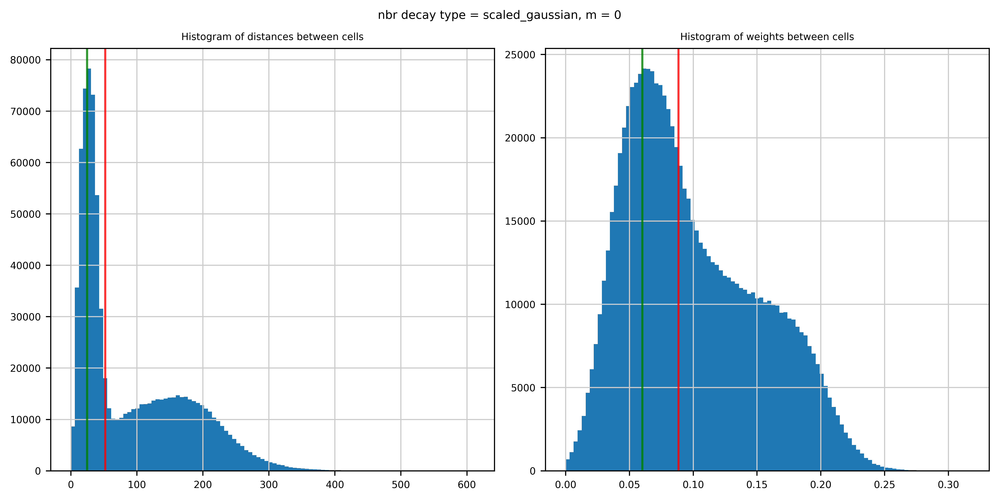

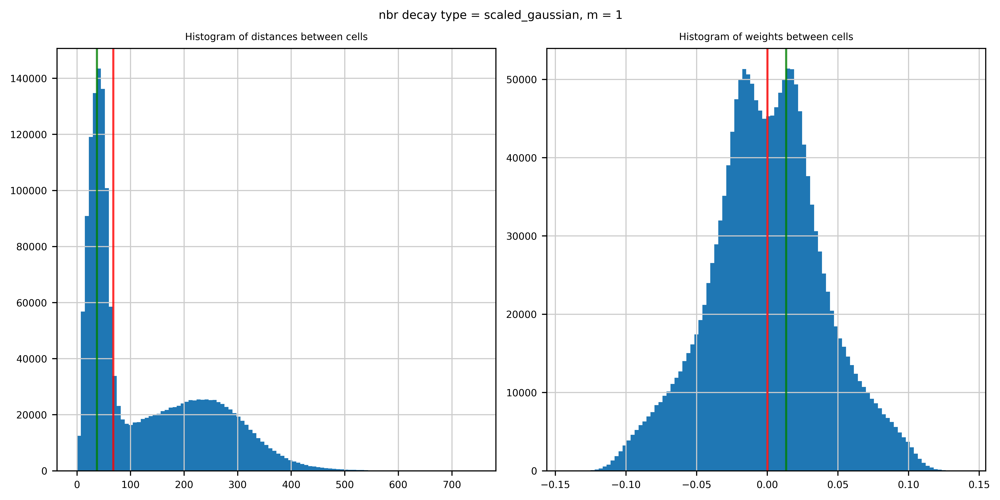

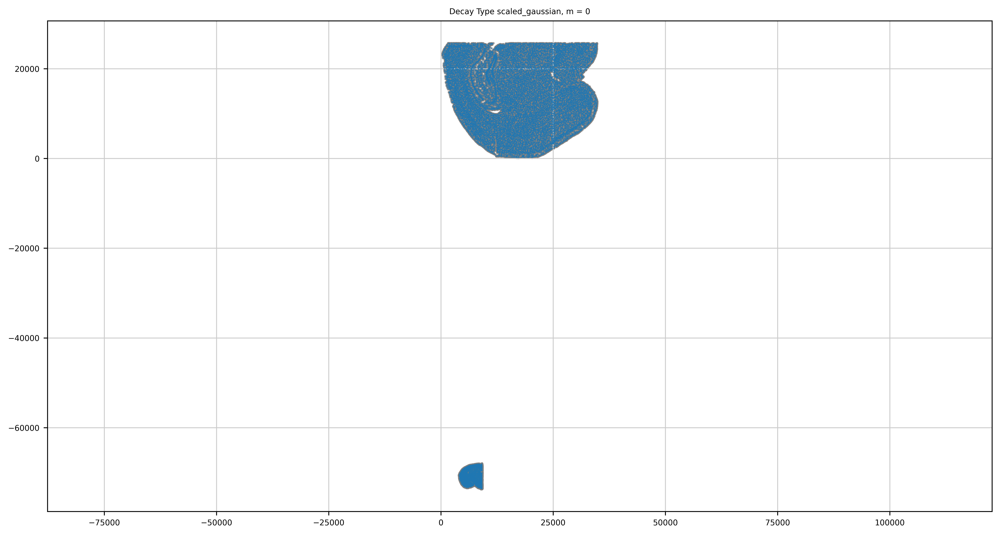

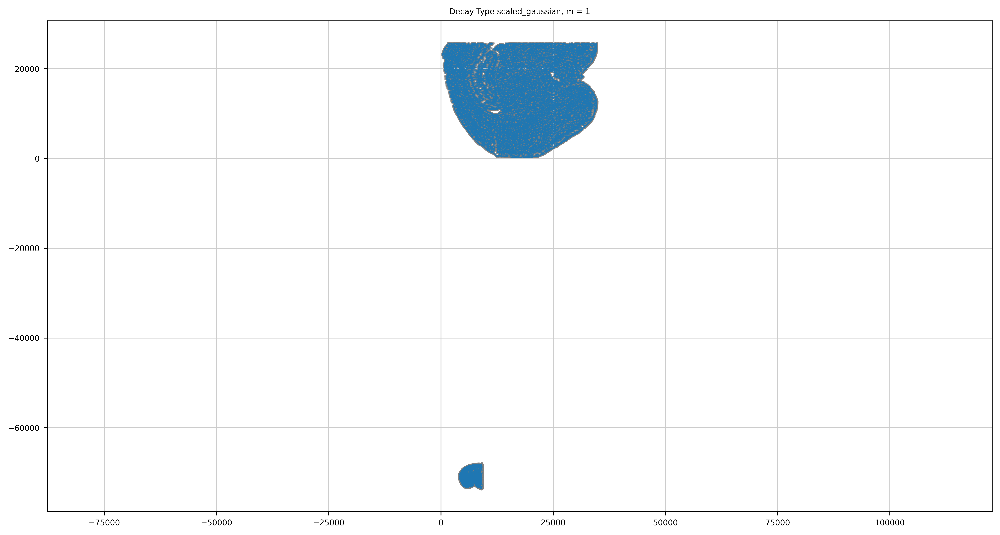

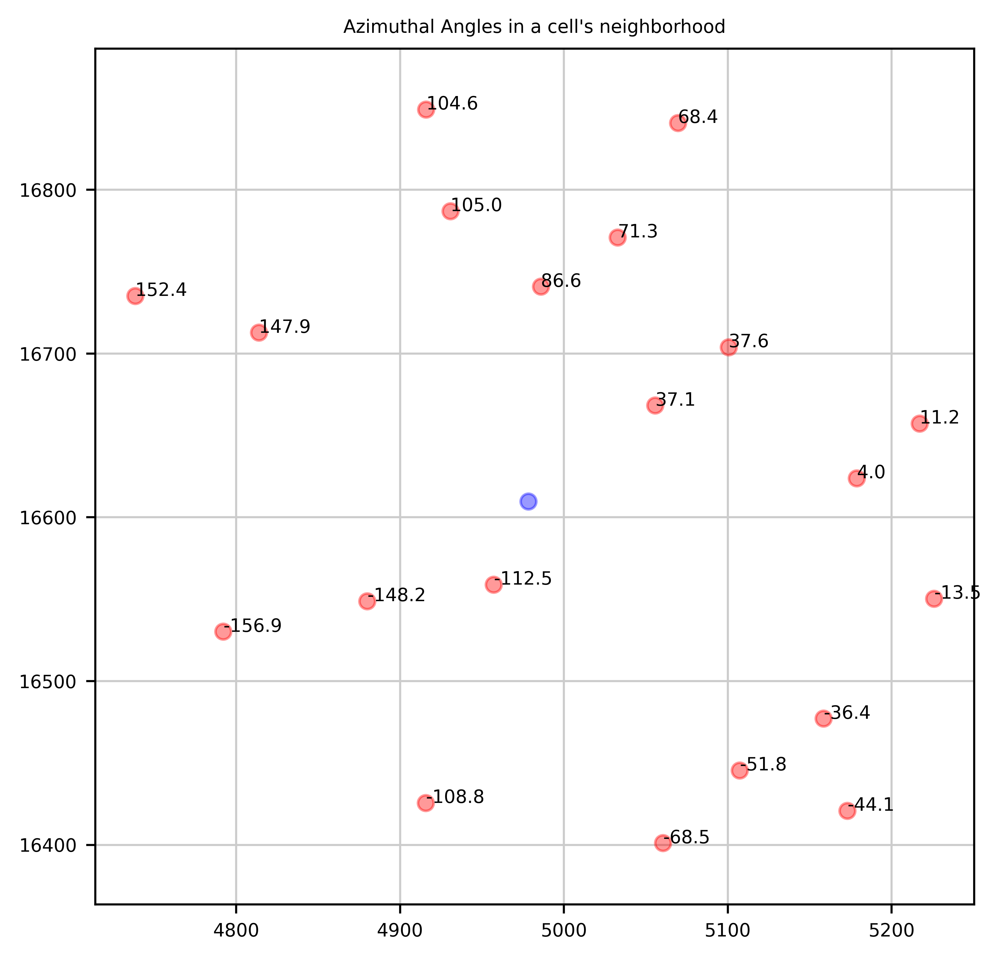

In [61]:
from banksy.initialize_banksy import initialize_banksy

banksy_dict = initialize_banksy(
    adata,
    coord_keys,
    n_neighs,
    nbr_weight_decay=nbr_weight_decay,
    max_m=max_m,
    plt_edge_hist=True,
    plt_nbr_weights=True,
    plt_agf_angles=False, # takes long time to plot
    plt_theta=True,
)

In [62]:
from banksy.embed_banksy import generate_banksy_matrix

# The following are the main hyperparameters for BANKSY
# -----------------------------------------------------
resolutions = [0.7]  # clustering resolution for UMAP
pca_dims = [20]  # Dimensionality in which PCA reduces to
lambda_list = [0.2]  # list of lambda parameters

banksy_dict, banksy_matrix = generate_banksy_matrix(adata,
                                                    banksy_dict,
                                                    lambda_list,
                                                    max_m)

Runtime Apr-02-2026-15-24

431 genes to be analysed:
Gene List:
Index(['A2m', 'Abcc9', 'Abi3bp', 'Acta2', 'Adcyap1', 'Adgrg2', 'Adgrg6',
       'Adora1', 'Adora2a', 'Adra1b',
       ...
       'Ung', 'Vcan', 'Vgll3', 'Vipr2', 'Vwc2', 'Vwc2l', 'Wif1', 'Wnt4',
       'Zfhx4', 'Zic1'],
      dtype='object', name='gene_name', length=431)

Check if X contains only finite (non-NAN) values
Decay Type: scaled_gaussian
Weights Object: {'weights': {0: <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 857040 stored elements and shape (85704, 85704)>, 1: <Compressed Sparse Row sparse matrix of dtype 'complex128'
	with 1714080 stored elements and shape (85704, 85704)>}}

Nbr matrix | Mean: 0.2 | Std: 0.8
Size of Nbr | Shape: (85704, 431)
Top 3 entries of Nbr Mat:

[[0.         0.47333579 0.        ]
 [0.         0.         0.        ]
 [0.         0.         0.        ]]

AGF matrix | Mean: 0.1 | Std: 0.32
Size of AGF mat (m = 1) | Shape: (85704, 431)
Top entries of AGF:
[[0.03325178 0.

In [63]:
from banksy_utils.umap_pca import pca_umap

pca_umap(banksy_dict,
         pca_dims = pca_dims,
         add_umap = True,
         plt_remaining_var = False,
         )

Current decay types: ['scaled_gaussian']

Reducing dims of dataset in (Index = scaled_gaussian, lambda = 0.2)

Setting the total number of PC = 20
Original shape of matrix: (85704, 1293)
Reduced shape of matrix: (85704, 20)
------------------------------------------------------------
min_value = -33.48026552451242, mean = -7.417554130165833e-15, max = 127.99053763728908

Conducting UMAP and adding embeddings to adata.obsm["reduced_pc_20_umap"]
UMAP embedding
------------------------------------------------------------
shape: (85704, 2)


AxisArrays with keys: reduced_pc_20, reduced_pc_20_umap


In [64]:
embedding_key = 'banksy_latent'

In [65]:
adata.obsm[embedding_key] = banksy_dict[nbr_weight_decay][lambda_list[0]]["adata"].obsm["reduced_pc_20"]

In [66]:
import harmonypy

x = adata.obsm[embedding_key].astype('float64')
harmony_out = harmonypy.run_harmony(x, adata.obs, batch_key)
adata.obsm[f'{embedding_key}_harmony'] = harmony_out.Z_corr

2026-04-02 15:25:08,801 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-04-02 15:25:08,802 - harmonypy - INFO -   Parameters:
2026-04-02 15:25:08,803 - harmonypy - INFO -     max_iter_harmony: 10
2026-04-02 15:25:08,804 - harmonypy - INFO -     max_iter_kmeans: 20
2026-04-02 15:25:08,804 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-04-02 15:25:08,805 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-04-02 15:25:08,805 - harmonypy - INFO -     nclust: 100
2026-04-02 15:25:08,806 - harmonypy - INFO -     block_size: 0.05
2026-04-02 15:25:08,807 - harmonypy - INFO -     lamb: [1. 1.]
2026-04-02 15:25:08,808 - harmonypy - INFO -     theta: [2. 2.]
2026-04-02 15:25:08,809 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-04-02 15:25:08,809 - harmonypy - INFO -     verbose: True
2026-04-02 15:25:08,810 - harmonypy - INFO -     random_state: 0
2026-04-02 15:25:08,810 - harmonypy - INFO -   Data: 20 PCs × 85704 cells
2026-04-02 15:25:08,810 - harmonypy - INF

In [67]:
# Save updated AnnData
for col in adata.obs.columns:
    if isinstance(adata.obs[col].dtype, pd.CategoricalDtype):
        adata.obs[col] = adata.obs[col].astype(str).astype('category')

adata.obs['cell_id'] = adata.obs['cell_id'].astype(str)
adata.obs.index = adata.obs.index.astype(str)

def fix_arrow_strings(df):
    for col in df.columns:
        if isinstance(df[col].dtype, pd.CategoricalDtype):
            df[col] = df[col].astype(str).astype('category')
        elif isinstance(df[col].array, pd.arrays.ArrowExtensionArray):
            df[col] = df[col].astype(str)
    df.index = df.index.astype(str)
    return df

adata.obs = fix_arrow_strings(adata.obs)
adata.var = fix_arrow_strings(adata.var)

adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/banksy/{dataset_name}_embedded.h5ad')

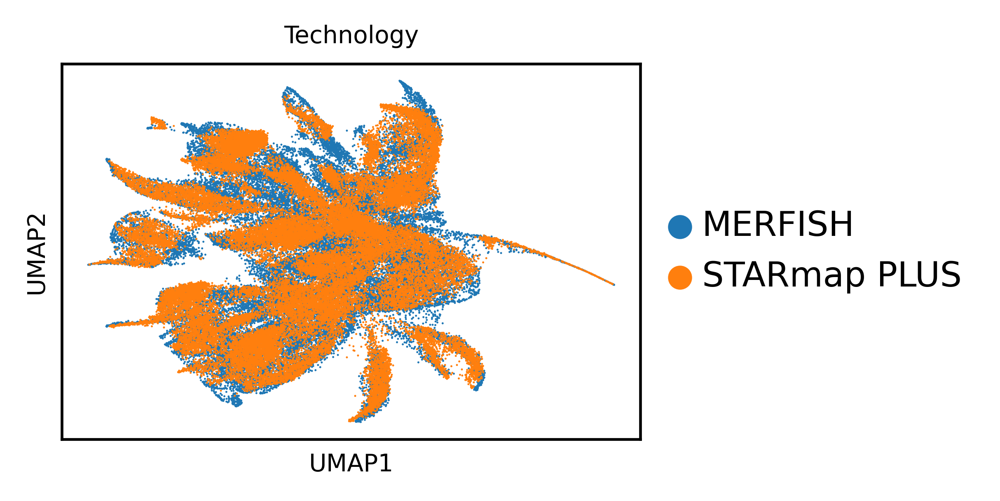

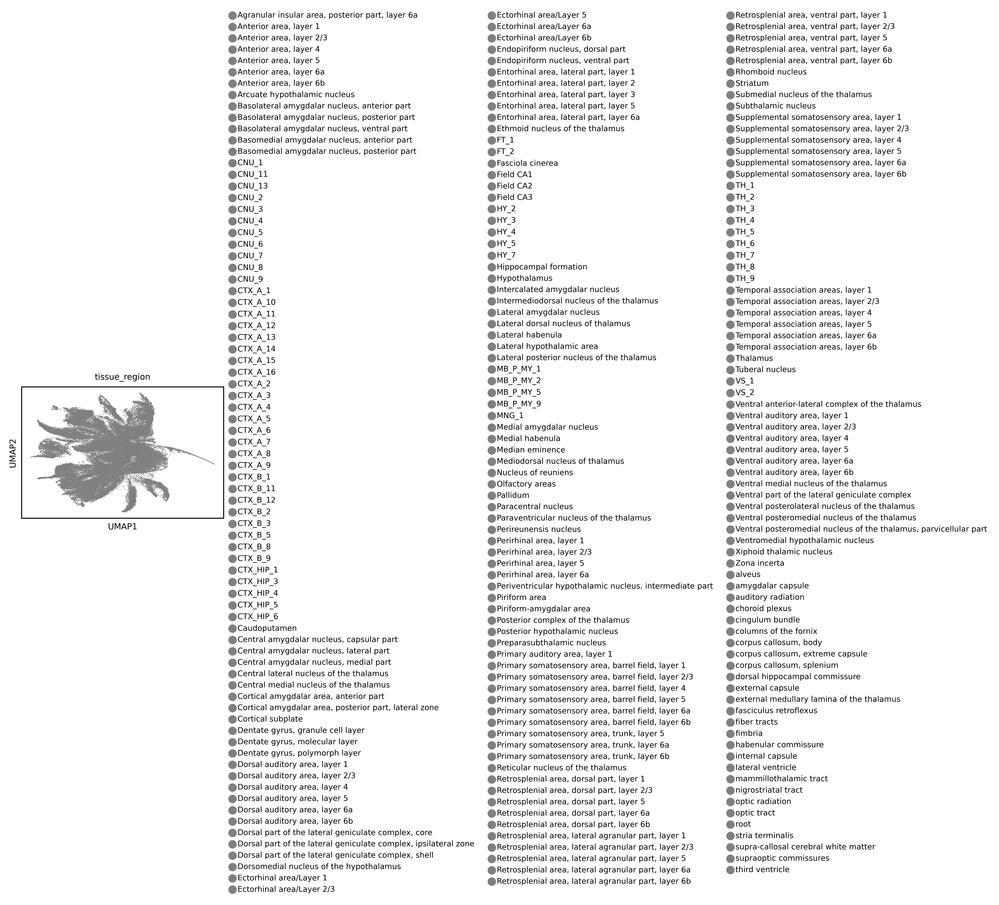

In [68]:
for emb_key in [f'{embedding_key}_harmony']:
    try:
        rsc.pp.neighbors(adata, n_neighbors=15, use_rep=emb_key,
                         n_pcs=n_pcs, key_added=emb_key)
        rsc.tl.umap(adata, neighbors_key=emb_key)
    except NameError:
        sc.pp.neighbors(adata, n_neighbors=15, use_rep=emb_key,
                        n_pcs=n_pcs, key_added=emb_key)
        sc.tl.umap(adata, neighbors_key=emb_key)

    n_pcs_string = f"_{n_pcs}_pcs" if n_pcs else ""
    categories = adata.obs[batch_key].cat.categories.tolist()
    assert len(categories) == 2, "Expected exactly 2 categories for batch_key"
    rename = dict(zip(sorted(categories), ["MERFISH", "STARmap PLUS"]))
    adata.obs[batch_key] = adata.obs[batch_key].map(rename).astype("category")

    sc.pl.umap(
        adata,
        color=batch_key,
        title="Technology",
        legend_loc="right margin",
        legend_fontsize=10,
        show=False,
    )
    for collection in plt.gca().collections:
        collection.set_rasterized(True)
    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/banksy/{dataset_name}_{emb_key}_umap_by_{batch_key}{n_pcs_string}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

    for label_key in label_keys:
        sc.pl.umap(adata, color=label_key, show=False)
        for collection in plt.gca().collections:
            collection.set_rasterized(True)
        plt.savefig(
            f"{benchmarking_artifacts_folder_path}/banksy/{dataset_name}_{emb_key}_umap_by_{label_key}{n_pcs_string}.svg",
            format="svg", bbox_inches="tight"
        )
        plt.show()
        plt.close()

In [69]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/banksy/{dataset_name}_embedded.h5ad')

print(f"Embeddings saved to {f'{benchmarking_artifacts_folder_path}/banksy/{dataset_name}_embedded.h5ad'} in obsm['{embedding_key}']")

Embeddings saved to /nfs/team361/sb75/nichejepa-reproducibility/artifacts/benchmarking/banksy/mmb0-1b_smb1-1b_1p_embedded.h5ad in obsm['banksy_latent']


In [70]:
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/banksy/{dataset_name}_embedded.h5ad')

In [71]:
latent_leiden_resolution = 0.8

In [72]:
# Plot embedding-based clusters
for emb_key in [f'{embedding_key}_harmony']:
    latent_cluster_key = f"{emb_key}_clusters_res_{latent_leiden_resolution}"
    
    try:
        rsc.tl.leiden(adata,
                      neighbors_key=emb_key,
                      key_added=latent_cluster_key,
                      resolution=latent_leiden_resolution,
                      flavor="igraph",
                      n_iterations=2)
    except NameError:
        sc.tl.leiden(adata,
                     neighbors_key=emb_key,
                     key_added=latent_cluster_key,
                     resolution=latent_leiden_resolution,
                     flavor="igraph",
                     n_iterations=2)

In [73]:
adata.obs[latent_cluster_key].value_counts()

banksy_latent_harmony_clusters_res_0.8
7     7300
13    6380
3     6309
19    5402
1     4742
10    4729
4     4639
11    4355
2     4017
12    3960
20    3925
15    3712
5     3227
6     3139
0     3091
16    2930
17    2782
23    2557
9     2386
8     1704
14    1386
21    1066
22     786
18     683
24     279
25     218
Name: count, dtype: int64

/tmp/ipykernel_2801720/1763585799.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/banksy/lib/python3.12/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


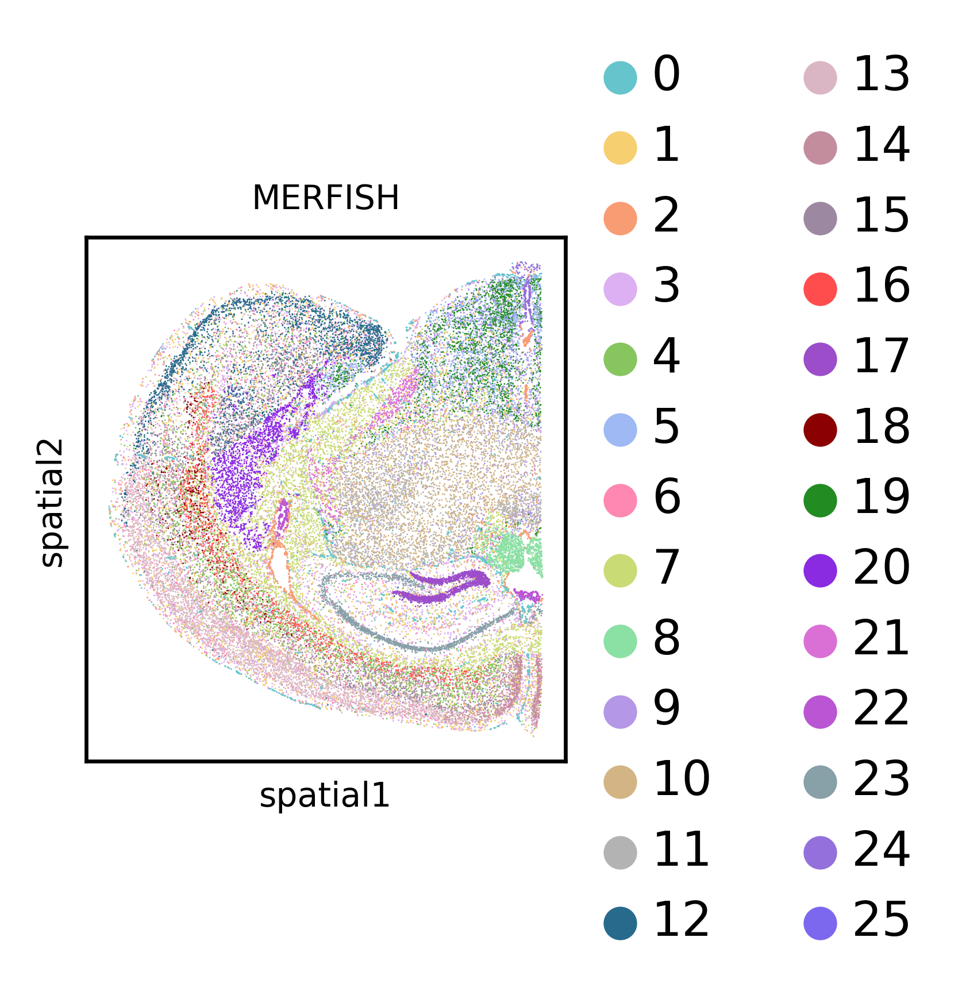

/tmp/ipykernel_2801720/1763585799.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/banksy/lib/python3.12/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


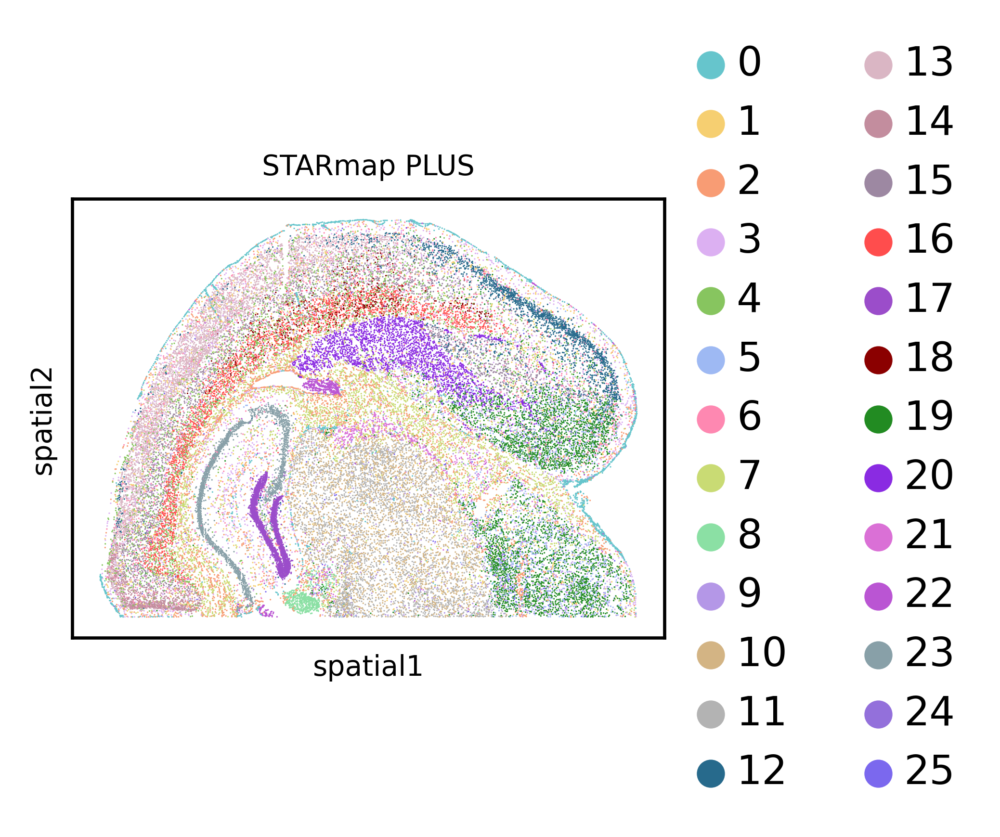

In [74]:
samples = adata.obs[batch_key].unique().tolist()
for sample in samples:
    adata_sample = adata[adata.obs[batch_key] == sample]
    sc.pl.spatial(
        adata_sample,
        color=latent_cluster_key,
        palette=custom_palette,
        spot_size=spot_sizes[sample],
        title=sample,
        legend_loc="right margin",
        legend_fontsize=10,
        show=False,
    )

    fig = plt.gcf()
    for ax in fig.axes:
        for child in ax.get_children():
            if isinstance(child, mpl.image.AxesImage):
                child.set_rasterized(True)
        for collection in ax.collections:
            collection.set_rasterized(True)

    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/banksy/tissue_{sample}_by_{latent_cluster_key}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

In [79]:
# Compute NMI with region annotations
mask = adata.obs["Sub_molecular_tissue_region"].notna()
labels_true = adata.obs.loc[mask, "Sub_molecular_tissue_region"]
labels_pred = adata.obs.loc[mask, latent_cluster_key]

nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
print(f"NMI (Sub_molecular_tissue_region): {nmi:.4f}")

mask = adata.obs["ccf_region_name"].notna()
labels_true = adata.obs.loc[mask, "ccf_region_name"]
labels_pred = adata.obs.loc[mask, latent_cluster_key]

nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
print(f"NMI (ccf_region_name): {nmi:.4f}")

NMI (Sub_molecular_tissue_region): 0.2911
NMI (ccf_region_name): 0.2632


In [81]:
# Compute iLISI
batch_key = "batch"
batch = adata.obs[batch_key].values

knn = pynndescent(adata.obsm[f'{embedding_key}_harmony'], n_neighbors=90)
score = ilisi_knn(knn, batch)
print(f"iLISI ({embedding_key}): {score:.4f}")

iLISI (banksy_latent): 0.3585


In [ ]:
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/banksy/{dataset_name}_embedded_clustered.h5ad')